# Aufgabe: Was steht auf dem Speiseplan?

In dieser Aufgabe findest du heraus, wie Menge und Art der Nahrung beeinflussen, wie schnell *E. coli* wächst.

In [1]:
setLanguage('de')   % Sprache der Ausgaben

Sprache: Deutsch


In [2]:
model = loadEcoli();

Modell geladen: E.-coli-Kernmodell mit 95 Reaktionen, 72 Metaboliten und 137 Genen.


## Mehr Zucker, schnelleres Wachstum?

Jede Nahrung hat eine **Austauschreaktion** (*exchange reaction*), deren ID mit `EX_` beginnt. Glukose ist `EX_glc__D_e`. Mit `changeRxnBounds` legst du fest, wie viel davon die Zelle aufnehmen darf. Die Menge ist negativ, denn Aufnehmen heißt, dass der Stoff die Umgebung *verlässt*.

Die Zelle unten probiert Glukosemengen von 0 bis 20 aus. Führe sie aus.

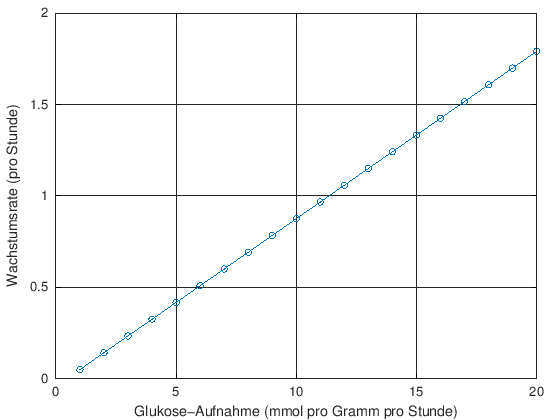

In [3]:
glucose = 0:1:20;
growth = zeros(size(glucose));
for i = 1:numel(glucose)
  m = changeRxnBounds(model, 'EX_glc__D_e', -glucose(i), 'l');   % so viel Glukose erlauben
  s = optimizeCbModel(m);
  growth(i) = s.f;
end
plot(glucose, growth, 'o-', 'linewidth', 2)
xlabel('Glukose-Aufnahme (mmol pro Gramm pro Stunde)')
ylabel('Wachstumsrate (pro Stunde)')
grid on

**Frage 1:** Welche Form hat die Linie? Was passiert mit der Wachstumsrate, wenn du die Glukose verdoppelst?

✅ **Antwort:** Eine **gerade Linie**: doppelt so viel Glukose ergibt doppelt so viel Wachstum (5 → 0,42, 10 → 0,87, 20 → 1,79 pro Stunde). Mit sehr wenig Glukose (unter etwa einer halben Einheit) gibt es kein Wachstum, weil die Zelle zuerst Energie braucht, nur um am Leben zu bleiben (*Erhaltungsstoffwechsel*). Ganz ohne Glukose findet das Modell keine Lösung, darum fehlt der Punkt bei 0. In einer echten Zelle würde die Linie irgendwann flach werden, weil die Transporter, die Zucker in die Zelle bringen, nur begrenzt schnell arbeiten.

## Andere Nahrung

*E. coli* kann auch von anderer Nahrung leben. In der Zelle unten wird die Glukose abgeschaltet (0), und die Zelle bekommt stattdessen 10 Einheiten **Acetat** (`EX_ac_e`).

In [4]:
m = changeRxnBounds(model, 'EX_glc__D_e', 0, 'l');   % keine Glukose
m = changeRxnBounds(m, 'EX_ac_e', -10, 'l');          % 10 Einheiten Acetat
showGrowth(m);

Wachstumsrate: 0.173 pro Stunde (die Zellen verdoppeln sich alle 240 Minuten).


Jetzt bist du dran. Probiere **Fruktose** (Fruchtzucker, `EX_fru_e`) und **Succinat** (`EX_succ_e`) aus. Ersetze `___` durch die ID der Nahrung.

| Nahrung | ID | Wachstumsrate (pro Stunde) |
|---|---|---|
| Glukose | `EX_glc__D_e` | 0,874 |
| Acetat | `EX_ac_e` | |
| Fruktose | `EX_fru_e` | |
| Succinat | `EX_succ_e` | |

*Doppelklicke auf die Tabelle, um deine Ergebnisse einzutragen.*

In [5]:
m = changeRxnBounds(model, 'EX_glc__D_e', 0, 'l');   % keine Glukose
m = changeRxnBounds(m, 'EX_fru_e', -10, 'l');         % 10 Einheiten einer anderen Nahrung
showGrowth(m);
m = changeRxnBounds(model, 'EX_glc__D_e', 0, 'l');
m = changeRxnBounds(m, 'EX_succ_e', -10, 'l');
showGrowth(m);

Wachstumsrate: 0.874 pro Stunde (die Zellen verdoppeln sich alle 48 Minuten).


Wachstumsrate: 0.398 pro Stunde (die Zellen verdoppeln sich alle 105 Minuten).


**Frage 2:** Welche Nahrung ist für *E. coli* am besten, welche am schlechtesten? Glukose und Fruktose haben **6** Kohlenstoffatome pro Molekül, Succinat hat **4** und Acetat nur **2**. Kannst du die Ergebnisse damit erklären?

✅ **Antwort:** Glukose und Fruktose: 0,874, Succinat: 0,398, Acetat: 0,173 pro Stunde. Glukose und Fruktose sind gleich gut. Die Zelle bekommt aus beiden gleich viel Material und Energie, weil Fruktose in dieselben Zwischenprodukte umgewandelt wird. Je weniger Kohlenstoffatome ein Molekül hat, desto weniger Baumaterial und Energie bekommt die Zelle aus jedem Molekül, also wächst sie langsamer.

**Extra:** Kann *E. coli* **ohne Sauerstoff** von Acetat leben? Probiere es mit `setMedium(m, 0, 0)` aus, nachdem du ihm Acetat gegeben hast.

In [6]:
m = changeRxnBounds(model, 'EX_ac_e', -10, 'l');
m = setMedium(m, 0, 0);   % keine Glukose, kein Sauerstoff
showGrowth(m);

Nahrung: Glukose-Aufnahme bis 0, Sauerstoff-Aufnahme bis 0 (mmol pro Gramm pro Stunde).


Keine Lösung: unter diesen Bedingungen kann das Modell nicht laufen.


✅ **Antwort:** Nein. Acetat ist selbst schon ein Abfallprodukt der Gärung, ohne Sauerstoff ist daraus keine Energie mehr zu holen. Das Modell findet überhaupt keine Lösung, weil die Zelle nicht einmal die Energie herstellen kann, die sie zum Überleben braucht.

**Fertig!** Weiter geht es mit `04_exercise_knockouts.ipynb`.

<small>Modell: *E.-coli*-Kernmodell aus BiGG Models (Orth et al. 2010; King et al. 2016). Software: COBRA Toolbox (Heirendt et al. 2019) in GNU Octave. Vollständige Quellen am Ende von `01_tutorial_fba.ipynb`.</small>